# Lab 7: Gradient-Based Methods
We will apply gradient-based methods to tabular datasets in this laboratory (images will be the focus of the following lecture).

We will use ```pytorch``` for the neural networks's implementation and ```captum``` for the explanations one. 

Documentation on ```captum``` can be found at [this link](https://captum.ai/): it is a library developed by Meta which allows us to compute explanations built on top of ```pytorch```.

You can install the library with either of the following commands:

```conda install captum -c pytorch ```

```pip install captum```

Installation requirements are: Python $\geq$ 3.6, PyTorch $\geq$ 1.2 and numpy.


In [ ]:
!pip install captum

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F

import captum

import warnings
warnings.filterwarnings('ignore')

/Users/lucabortolussi/anaconda3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


We will use and compare the methods we have proposed in class, namely: Saliency, Input X Gradient, DeepLift, Integrated Gradients and LRP.

The attributions algorithms in ```captum``` are classified as:
- Primary Attributions: compute the contribution of each input feature to the output of the model.
- Layer Attributions: compute the contribution of each neuron in a given layer to the output of the model.
- Neuron Attributions: compute the contribution of each input feature to the activation of a selected (hidden) neuron.

In [3]:
# Primary attributions
from captum.attr import Saliency, InputXGradient, DeepLift, IntegratedGradients, LRP

#Layer attributions
from captum.attr import LayerGradientXActivation, LayerDeepLift, LayerIntegratedGradients, LayerLRP 
### LayerGradient X Activation is the tailored version of Input X Gradient for layer attributions

#Neuron attributions
from captum.attr import NeuronDeepLift, NeuronIntegratedGradients
### There is no implementation of NeuronLRP available at this time

From the tutorials available on the captum documentation, let us investigate the Titanic dataset, as a warm up example.

- Dataset preprocessing


In [4]:
df = pd.read_csv("titanic3.csv")
print(df.shape)
df.head()

(1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [5]:
df = pd.concat([df, 
                pd.get_dummies(df['sex']).astype(int), 
                pd.get_dummies(df['embarked'], prefix = "embark").astype(int), 
                pd.get_dummies(df['pclass'], prefix='class').astype(int)], 
                axis=1)

df['age'] = df['age'].fillna(df['age'].mean())
df['fare'] = df['fare'].fillna(df['fare'].mean())

df.drop(['name', 'ticket', 'cabin', 'boat', 'body', 'home.dest', 'sex', 'embarked', 'pclass'],axis=1, inplace= True)

In [6]:
df.head()

,survived,age,sibsp,parch,fare,female,male,embark_C,embark_Q,embark_S,class_1,class_2,class_3
0,1,29.00,0,0,211.3375,1,0,0,0,1,1,0,0
1,1,0.92,1,2,151.5500,0,1,0,0,1,1,0,0
2,0,2.00,1,2,151.5500,1,0,0,0,1,1,0,0
3,0,30.00,1,2,151.5500,0,1,0,0,1,1,0,0
4,0,25.00,1,2,151.5500,1,0,0,0,1,1,0,0


In [7]:
y = df.pop('survived').to_numpy()
X = df.to_numpy()
feature_names = list(df.columns)

In [8]:
print(X.shape, y.shape)

(1309, 12) (1309,)


In [9]:
Xtrain, Xtest, ytrain,ytest = train_test_split(X, y, test_size=0.2)

In [10]:
def standardize_col(x):
    return (x-np.mean(x))/np.std(x)

In [11]:
Xtrain[:,0] = standardize_col(Xtrain[:,0]) #age
Xtrain[:,3] = standardize_col(Xtrain[:,3]) #fare

Xtest[:,0] = standardize_col(Xtest[:,0]) #age
Xtest[:,3] = standardize_col(Xtest[:,3]) #fare

In [12]:
Xtrain[:2,:]

array([[ 0.00582447,  0.        ,  0.        , -0.48357192,  1.        ,
         0.        ,  0.        ,  1.        ,  0.        ,  0.        ,
         0.        ,  1.        ],
       [ 1.68995635,  0.        ,  1.        ,  0.48167116,  0.        ,
         1.        ,  1.        ,  0.        ,  0.        ,  1.        ,
         0.        ,  0.        ]])

In [13]:
X_train = torch.Tensor(Xtrain)
X_test = torch.Tensor(Xtest)
y_train = F.one_hot(torch.tensor(ytrain)).to(torch.float)
y_test = F.one_hot(torch.tensor(ytest)).to(torch.float)

- Model definition and training

In [14]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear1= nn.Linear(12,12)
        self.relu1 = nn.ReLU()
        self.linear2 = nn.Linear(12,8)
        self.relu2 = nn.ReLU()
        self.linear3 = nn.Linear(8,2)
        self.softmax = nn.Softmax(dim=1)
    
    def forward(self,X):
        out = self.linear1(X)
        out = self.relu1(out)
        out = self.linear2(out)
        out = self.relu2(out)
        out = self.linear3(out)
        return self.softmax(out)

In [15]:
def train_net(model, Xtrain, ytrain, loss_fn, optimizer, n_epochs = 100, model_name = 'nome'):
    
    for epoch in range(n_epochs):
        y_hat = model(Xtrain)
        loss = loss_fn(y_hat, ytrain)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 20 ==0:
            print(f"Epoch {epoch}/{n_epochs}")
    
    torch.save(model.state_dict(), f"{model_name}.pt")

In [16]:
model = SimpleNet()
model_name = 'titanic'

loss_fn = nn.CrossEntropyLoss()
lr = 0.1
optimizer = torch.optim.Adam(model.parameters(), lr = lr)


load_model = True

if load_model:
    model.load_state_dict(torch.load(f"{model_name}.pt"))
else:
    train_net(model, X_train, y_train, loss_fn, optimizer,n_epochs = 200, model_name=model_name)

In [17]:
y_hat = model(X_train).detach().numpy()
print("Train_accuracy", np.round(100*np.mean(np.argmax(y_hat, axis=1)==ytrain), 2))

Train_accuracy 82.33


In [18]:
y_hat = model(X_test).detach().numpy()
print("Test_accuracy", np.round(100*np.mean(np.argmax(y_hat, axis=1)==ytest), 2))

Test_accuracy 85.5


- Primary attributions

In [19]:
def add_labels(x, y):
    for i in range(len(x)):
        plt.text(i, y[i], np.round(y[i],3), ha='center')

def plot_attributions_bar(attributions, feature_names, average=False):
    plt.figure(figsize=(12,6))
    title = "Feature attributions"

    if average:
        attributions = np.mean(attributions, axis=0)
        title = title + " (Average)"

    x = range(len(feature_names))
    plt.bar(x, attributions, align='center')
    plt.xticks(x, feature_names, rotation=45)
    plt.xlabel("Features")
    add_labels(x, attributions)
    plt.title(title)
    plt.show()

Once the method is instantiated , we can compute the attributions on the training set. 
In a classification scenario, we need to define the target: it is the index of the neuron corresponding to the class we wish to explain. In this case, ```target = 1``` corresponds to the class _survived_.
Note that, for every datapoint, we will obtain explanations favouring the selected class. A negative attributions means that the feature is against the classification (and hence favours the other possible class).

For a regression scenario, the target is automatically derived as there is only one neuron in the output layer. 

In [20]:
method = IntegratedGradients(model)
X_train.requires_grad_()
attr = method.attribute(X_train, target=1).detach().numpy()

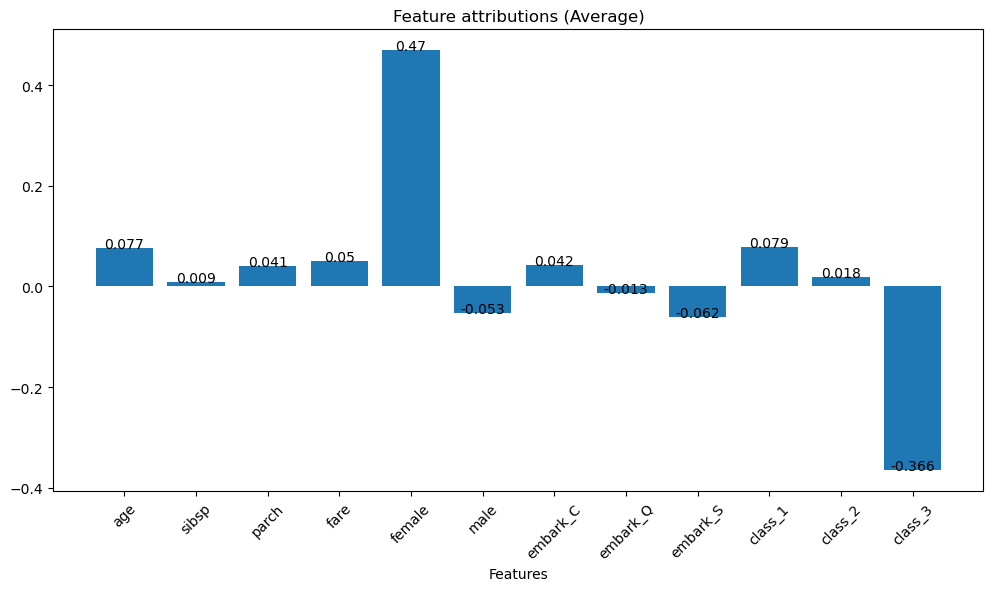

In [21]:
plot_attributions_bar(attr, feature_names, average=True)

Average attributions are not always useful, as we are dealing with local explanations. Let us investigate a randomly selected point and its explanation.
Run the following chunk multiple times to investigate different examples. 

Is the explanation useful when all the attributions are close to zero for a given point? What could you do to understand a model's behaviour for such instances?

340


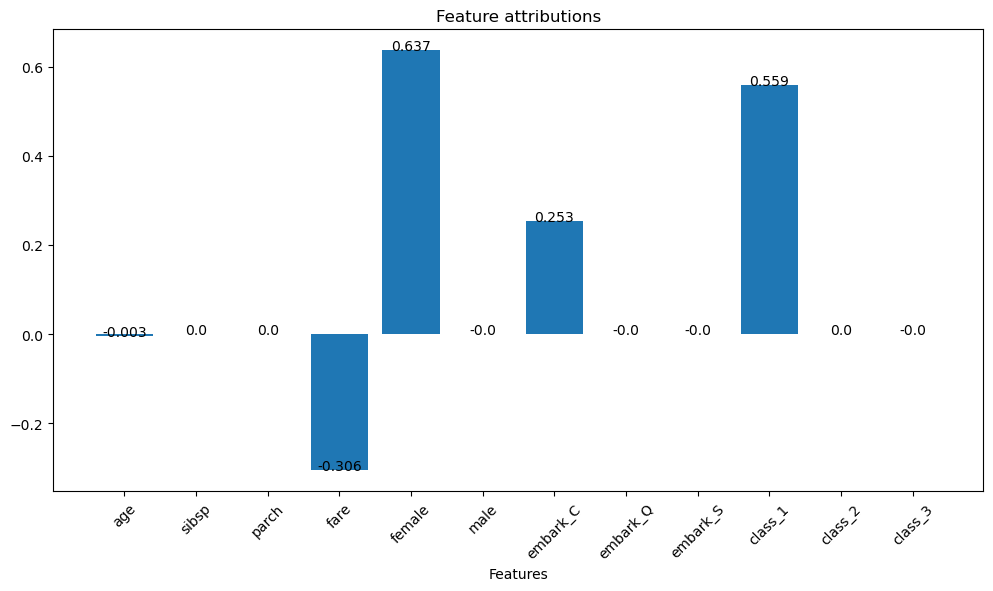

In [22]:
idx = np.random.choice(range(Xtrain.shape[0]),1)[0]
print(idx)
plot_attributions_bar(attr[idx,:], feature_names)

Did we explicitely indicate a baseline? 

What do you think is set as a default?

- Layer attributions

Let us investigate the influences of the neurons in the first hidden layer. 

In [23]:
method = LayerIntegratedGradients(model, model.relu1)
X_train.requires_grad_()
attr = method.attribute(X_train, target=1).detach().numpy()
print(attr.shape)

(1047, 12)


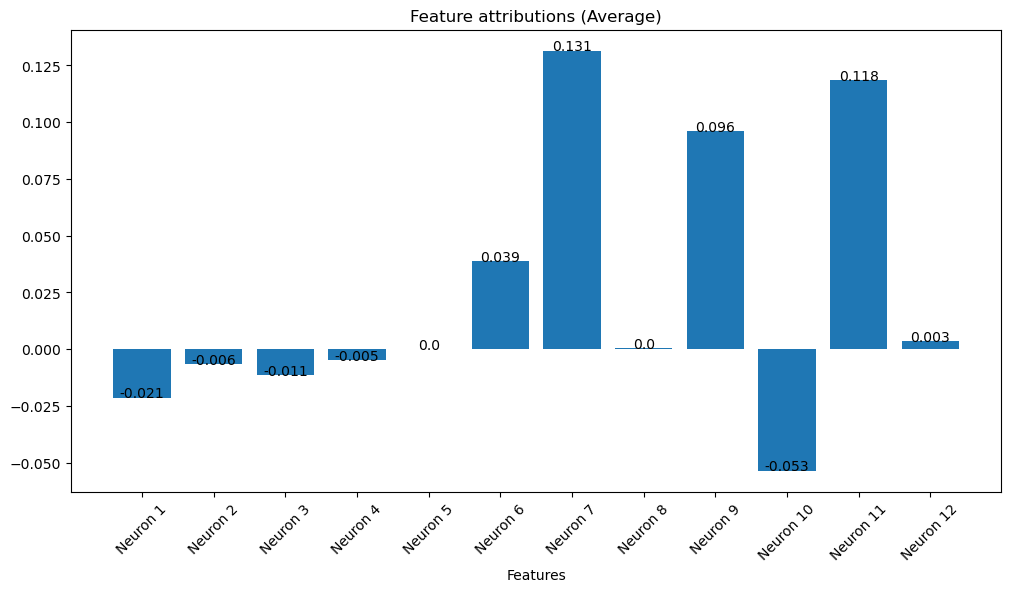

In [24]:
plot_attributions_bar(attr, [f"Neuron {i+1}" for i in range(12)], average=True)

340


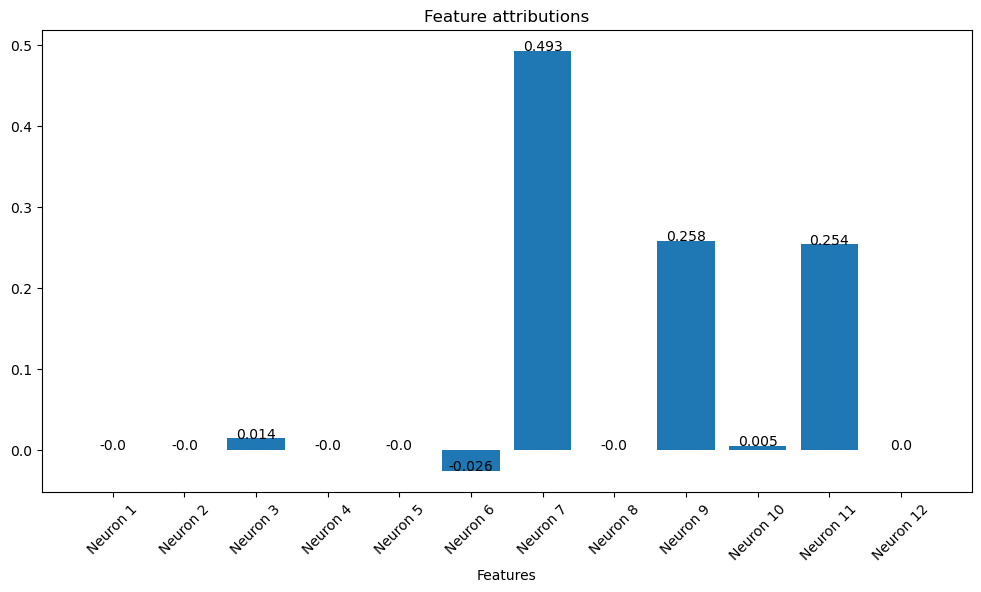

In [25]:
#idx = np.random.choice(range(Xtrain.shape[0]),1)[0]
print(idx)
plot_attributions_bar(attr[idx,:], [f"Neuron {i+1}" for i in range(12)])

Which neurons appear to have learned the most?

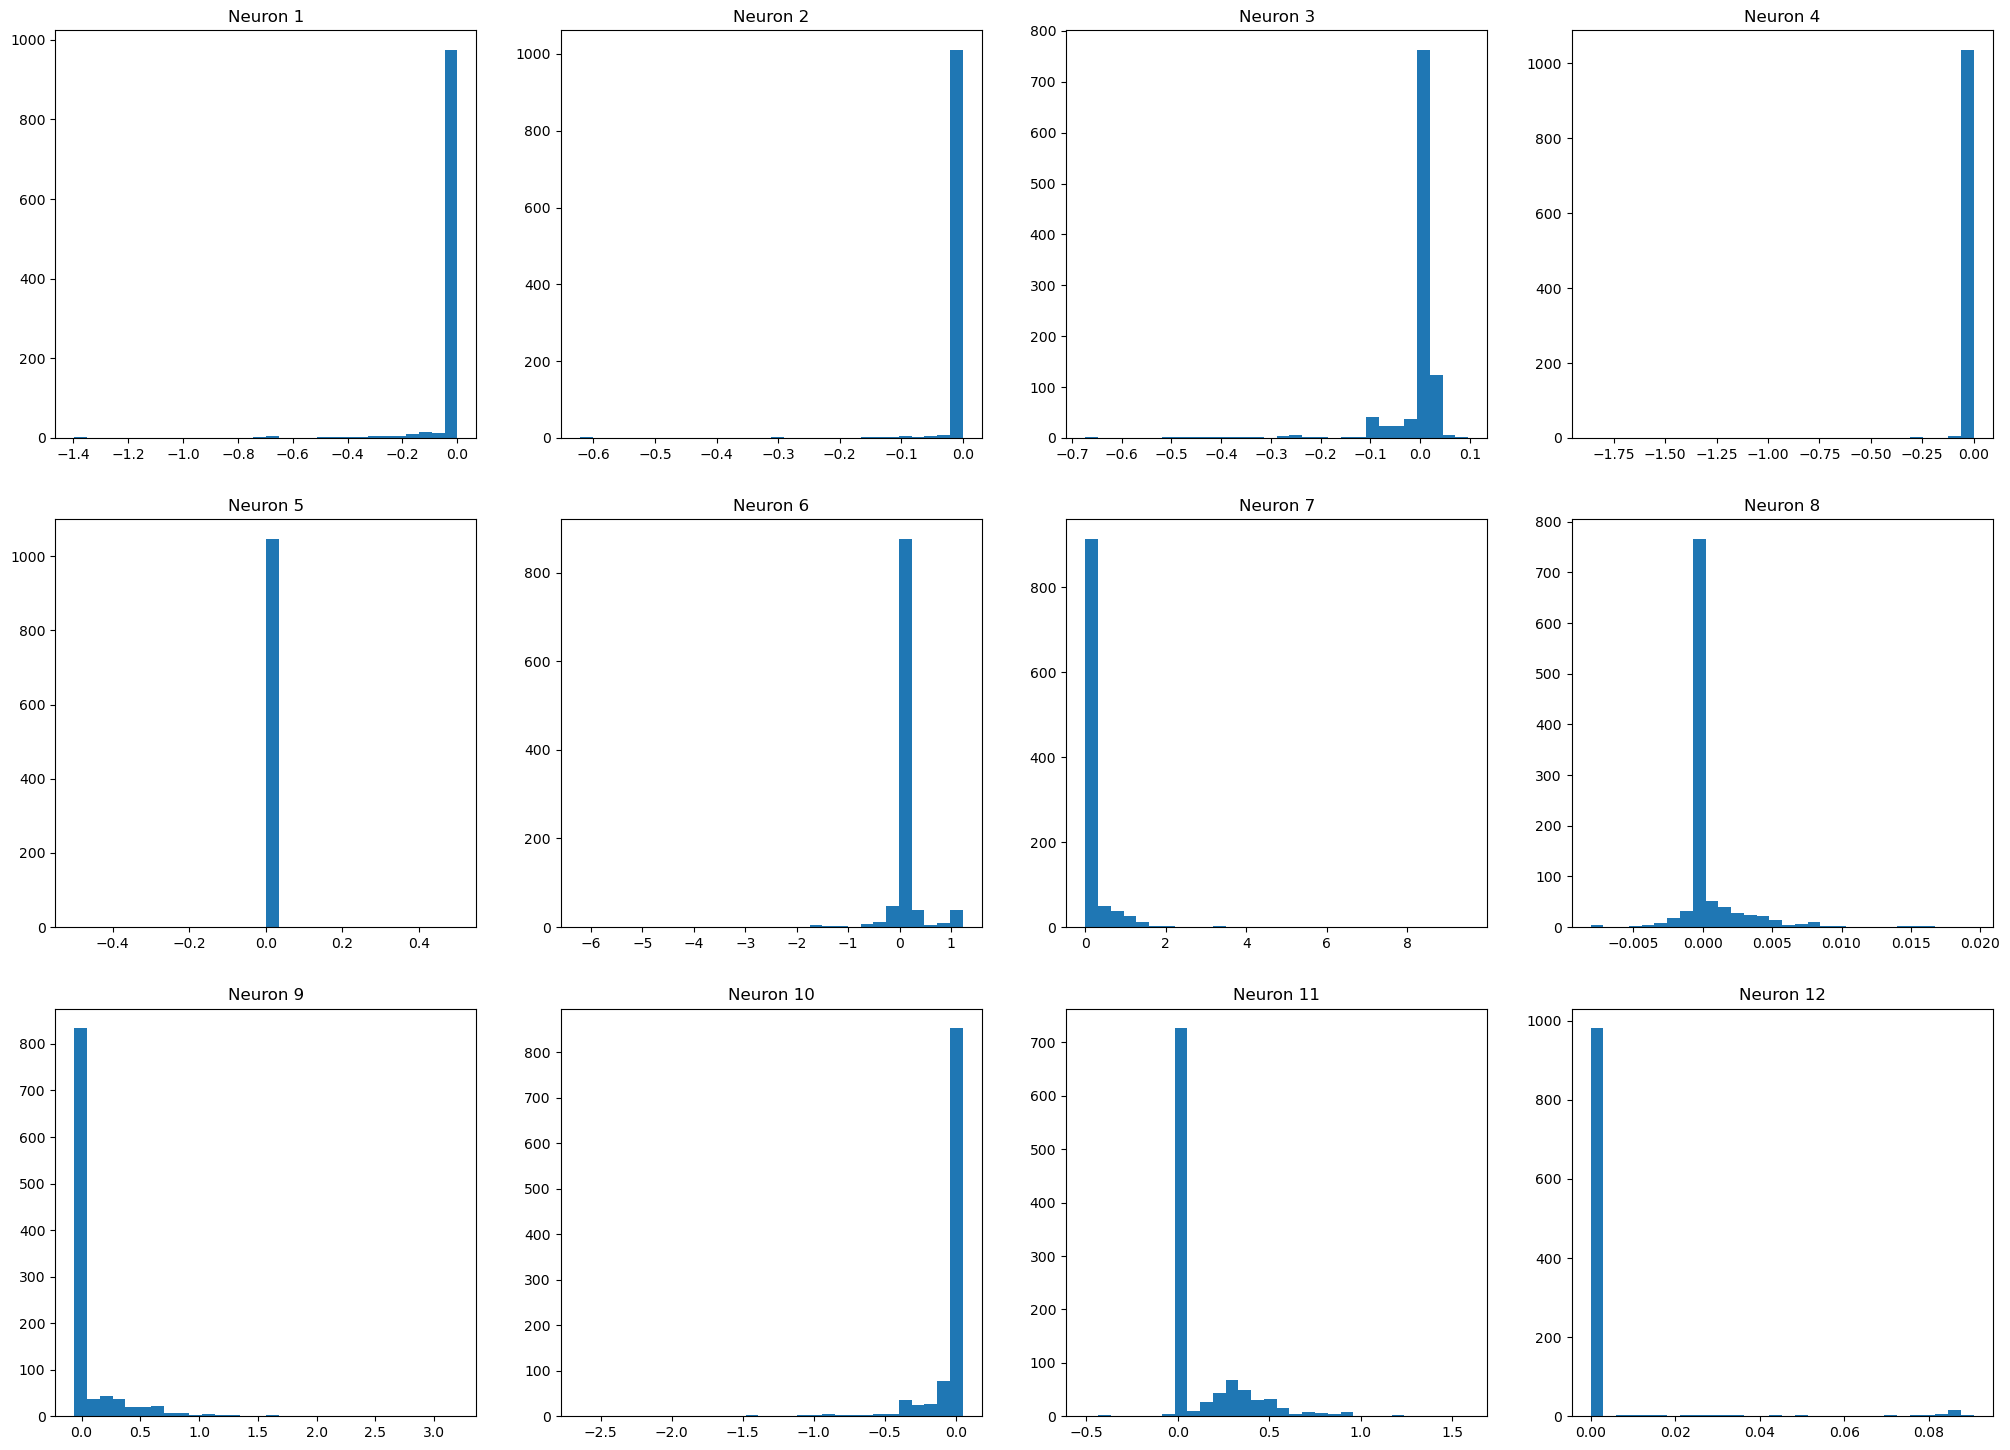

In [26]:
fig, ax = plt.subplots(3,4, figsize=(25, 18))

for neuron in range(12):
    ax_ = ax[neuron//4][neuron%4]
    ax_.hist(attr[:,neuron], bins=30)
    ax_.set_title(f"Neuron {neuron+1}")
plt.show()

Some neurons seem to be learning important features. Which features are influencing them?
- Neuron attributions

In [27]:
method = NeuronIntegratedGradients(model, model.relu1)
X_train.requires_grad_()

neuron = 4

attr = method.attribute(X_train, neuron_selector = neuron -1 ).detach().numpy()
print(attr.shape)

#Note that this method is equivalent to applying integrated gradients where the output is the output of the identified neuron. (that is why 'target=1' is missing as argument)

(1047, 12)


In [28]:
print(attr[:15,:]) #not all datapoints activate the neuron

[[ 0.          0.          0.         -0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [ 0.27007515 -0.          0.1750704   0.2191618  -0.          0.29193676
   0.08873413 -0.         -0.         -0.15631207 -0.         -0.        ]
 [-0.          0.          0.         -0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [-0.          0.          0.         -0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.         -0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [-0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.         -0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [-0.

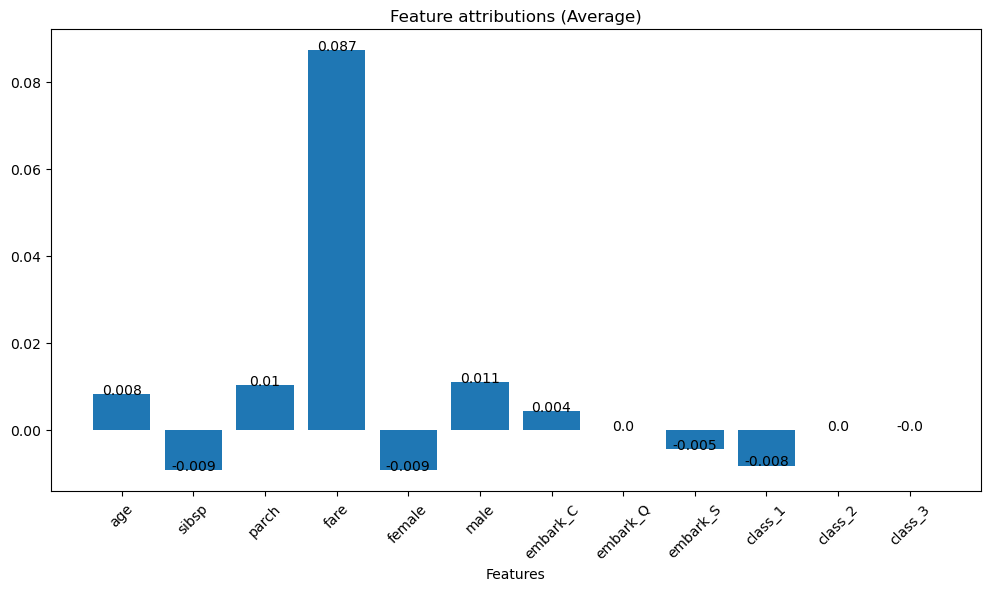

In [29]:
plot_attributions_bar(attr, feature_names, average=True)

# Exercises:
- Verify the coincidence between Input X Gradient and Saliency (multiply saliency by its input).
- Apply DeepLift (Primary, Layer, Neuron) to the dataset, what changes can you see with respect to Integrated Gradients?
- What happens when you try to apply LRP? Look at the source code to understand what happens.
- Choose a tabular dataset of your choice (classification or regression) and apply the techniques we have seen. Compare the results for at least 3 datapoints.